In [1]:
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import sacc
import pyccl as ccl
import mfcs
from functools import partial

In [2]:
planck_names = ['Planck__NPIPEnu100', 'Planck__NPIPEnu143', 'Planck__NPIPEnu217',
                'Planck__NPIPEnu353', 'Planck__NPIPEnu545', 'Planck__NPIPEnu857']
namefreq = {pn: pn.split("nu")[-1] for pn in planck_names}
gal_names = [f'DESI_BGS__{i}' for i in range(2)] + [f'DESI_LRG__{i}' for i in range(4)]

# Read (and fix) SACC file


In [3]:
s = sacc.Sacc.load_fits("../cls_cov.fits")

# We just need to fix the sacc file to add missing beams
fwhm = {
    "Planck__NPIPEnu030": 32.29,
    "Planck__NPIPEnu044": 27.94,
    "Planck__NPIPEnu070": 13.08,
    "Planck__NPIPEnu100": 9.66,
    "Planck__NPIPEnu143": 7.22,
    "Planck__NPIPEnu217": 4.90,
    "Planck__NPIPEnu353": 4.92,
    "Planck__NPIPEnu545": 4.67,
    "Planck__NPIPEnu857": 4.22,
}
nside = 1024
pixwin = hp.pixwin(nside, lmax=3*nside-1)
for pn in planck_names:
    beam = hp.gauss_beam(fwhm=np.deg2rad(fwhm[pn] / 60.0), lmax=3*nside-1)
    s.tracers[pn].beam = beam*pixwin

# Read bandpass data
In principle these could (should) be stored in the sacc file.

In [4]:
bandpasses = {pn: mfcs.BPass(fname=f"data/planck_bandpass/HFI_BANDPASS_F{namefreq[pn]}_reformat.txt" if int(namefreq[pn]) >= 100 else f"data/planck_bandpass/LFI_BANDPASS_F{namefreq[pn]}_reformat.txt") for pn in planck_names}

# Set up ingredients needed
- CIB SED model
- CIB and tSZ tracers
- tSZ SED (the CIB SED is included in the tracer)

In [5]:
# SED dictionary for the CIB
cosmo = ccl.CosmologyVanillaLCDM()
sed_u_file = "data/SIDES_SED/SED_U_finegrids.save"
bm = mfcs.SIDESBethermin(sed_u_file)
# Color correction to be implemented
color_corr = {
    "Planck__NPIPEnu100": 1.076,
    "Planck__NPIPEnu143": 1.017,
    "Planck__NPIPEnu217": 1.119,
    "Planck__NPIPEnu353": 1.097,
    "Planck__NPIPEnu545": 1.068,
    "Planck__NPIPEnu857": 0.995,
}
# SIDEs physical parameters
sides_params = {
    "logU_ms_int": 0.31,
    "logU_ms_slope": 0.69,
    "logU_sb_int": -0.25,
    "logU_sb_slope": 1.63,
    "sb_frac_at_z0": 0.015,
    "sb_frac_at_zsat": 0.030,
    "sb_zsat": 1.0,
    "Ums_zsat": 4.0,
    }

In [6]:
# CCL tracers for the CIB
zs = np.linspace(0.0001, 6.0, 100)
chis = ccl.comoving_radial_distance(cosmo, 1/(1+zs))
K = 1E-10  # Kennicut constant in Msun / yr / Lsun
CIB_sed = lambda nu: bm.sed_grid(zs, nu, cosmo, **sides_params).T

def CIB_tracer(cosmo, pn):
    Seff = bandpasses[pn].convolve(CIB_sed, fast=True)
    t = ccl.Tracer()
    t.add_tracer(cosmo, kernel=[chis, chis**2*Seff/K])
    return t

cib_tracers = {pn: partial(CIB_tracer, pn=pn) for pn in planck_names}
# The CIB SED is included in the tracers, so we just pass the color
# correction as its effective SED
cib_sed_dict = color_corr

# We just need one tracer for the tSZ
tsz_tracer = ccl.tSZTracer
# But we must provide the tSZ SED
tsz_sed_dict = {pn: bandpasses[pn].convolve(mfcs.tSZ_sed) for pn in planck_names}

# Create tomographer and run it

In [7]:
tomo = mfcs.LargeScaleTomographer(
    s, gal_names=gal_names, map_names=planck_names, comp_names=['tSZ', 'CIB'],
    tracer_classes={'tSZ': tsz_tracer, 'CIB': cib_tracers},
    seds={'tSZ': tsz_sed_dict, 'CIB': cib_sed_dict}, lmin=30)
                             

# Get tomographic biases
(running quick MCMC likelihood)

In [8]:
bgs, bUs, _, _ = tomo.get_linear_biases(nsteps=10000, burnin=2000)

Plot the result

Text(0, 0.5, '$b_g$')

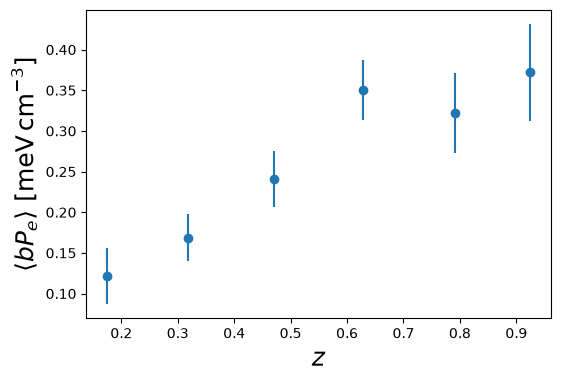

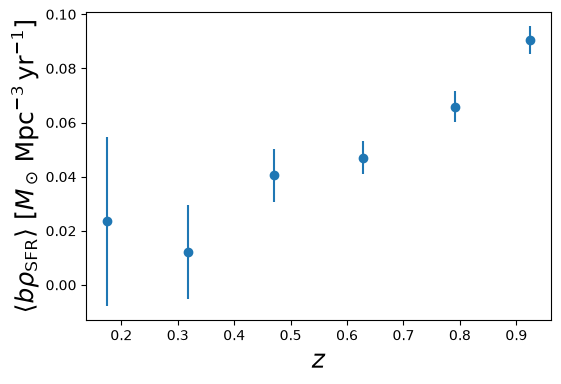

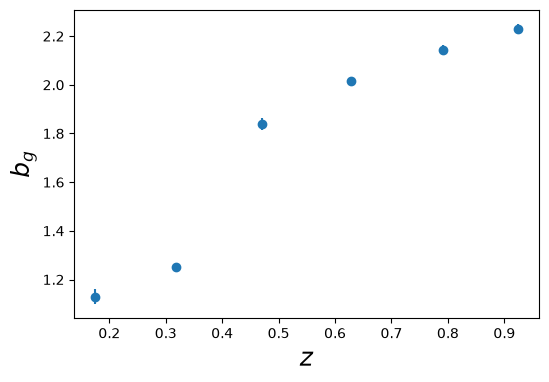

In [9]:
zz = np.array([tomo.tracer_data[gal_name]['z_mean'] for gal_name in tomo.gal_names])
bPes_mean = np.array([bUs[(gal_name, 'tSZ')][0] for gal_name in tomo.gal_names])*1E3
bPes_std = np.array([bUs[(gal_name, 'tSZ')][1] for gal_name in tomo.gal_names])*1E3
bPes_bf = np.array([bUs[(gal_name, 'tSZ')][2] for gal_name in tomo.gal_names])*1E3
brss_mean = np.array([bUs[(gal_name, 'CIB')][0] for gal_name in tomo.gal_names])
brss_std = np.array([bUs[(gal_name, 'CIB')][1] for gal_name in tomo.gal_names])
brss_bf = np.array([bUs[(gal_name, 'CIB')][2] for gal_name in tomo.gal_names])
bgs_mean = np.array([bgs[gal_name][0] for gal_name in tomo.gal_names])
bgs_std = np.array([bgs[gal_name][1] for gal_name in tomo.gal_names])
bgs_bf = np.array([bgs[gal_name][2] for gal_name in tomo.gal_names])

plt.figure(figsize=(6, 4))
plt.errorbar(zz, bPes_mean, yerr=bPes_std, fmt='o')
plt.xlabel(r'$z$', fontsize=18)
plt.ylabel(r'$\langle bP_e\rangle\,\,[{\rm meV}\,{\rm cm}^{-3}]$', fontsize=18)
plt.figure(figsize=(6, 4))
plt.errorbar(zz, brss_mean, yerr=brss_std, fmt='o')
plt.xlabel(r'$z$', fontsize=18)
plt.ylabel(r'$\langle b\rho_{\rm SFR}\rangle\,\,[M_\odot \,{\rm Mpc}^{-3}\,{\rm yr}^{-1}]$', fontsize=18)
plt.figure(figsize=(6, 4))
plt.errorbar(zz, bgs_mean, yerr=bgs_std, fmt='o')
plt.xlabel(r'$z$', fontsize=18)
plt.ylabel(r'$b_g$', fontsize=18)